Predicted States: [1 0 1 0 1]
Accuracy: 1.0
Document Boundaries: [0 2 4]

Document 1
Invoice number 101 customer details total amount
Invoice payment details billing address

Document 2
Report title introduction and summary
Report findings conclusion

Document 3
Invoice number 102 payment information


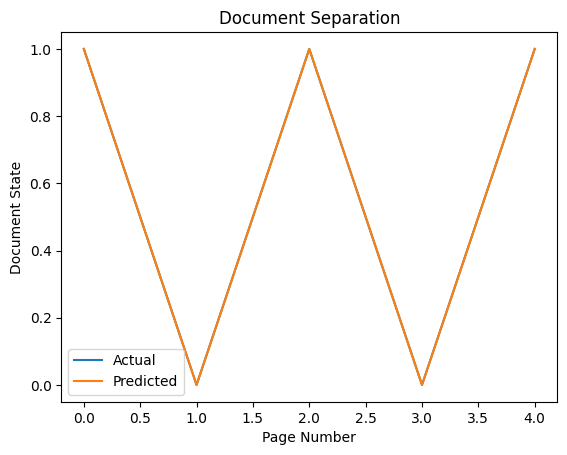

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score


pages = [
    "Invoice number 101 customer details total amount",
    "Invoice payment details billing address",
    "Report title introduction and summary",
    "Report findings conclusion",
    "Invoice number 102 payment information"
]


X = np.array([
    [0.75, 0.10, 0.90],
    [0.65, 0.15, 0.20],
    [0.20, 0.70, 0.85],
    [0.30, 0.60, 0.15],
    [0.80, 0.10, 0.95]
])


y = np.array([1, 0, 1, 0, 1])


model = GaussianNB()
model.fit(X, y)
prob = model.predict_proba(X)


T = np.ones((2, 2))

for i in range(len(y)-1):
    T[y[i], y[i+1]] += 1

T = T / T.sum(axis=1, keepdims=True)


def viterbi(P, T):
    dp = np.zeros_like(P)
    path = np.zeros(P.shape, dtype=int)

    dp[0] = np.log(P[0] + 1e-10)

    for t in range(1, len(P)):
        scores = dp[t-1][:, None] + np.log(T + 1e-10)
        path[t] = np.argmax(scores, axis=0)
        dp[t] = np.max(scores, axis=0) + np.log(P[t] + 1e-10)

    seq = [np.argmax(dp[-1])]

    for t in range(len(P)-1, 0, -1):
        seq.append(path[t, seq[-1]])

    return np.array(seq[::-1])


pred = viterbi(prob, T)


boundaries = np.where(pred == 1)[0]


documents = []
current = []

for i, page in enumerate(pages):
    if pred[i] == 1 and current:
        documents.append(current)
        current = []

    current.append(page)

if current:
    documents.append(current)


print("Predicted States:", pred)
print("Accuracy:", accuracy_score(y, pred))
print("Document Boundaries:", boundaries)

for i, doc in enumerate(documents):
    print("\nDocument", i+1)
    for page in doc:
        print(page)


plt.plot(y, label="Actual")
plt.plot(pred, label="Predicted")
plt.xlabel("Page Number")
plt.ylabel("Document State")
plt.title("Document Separation")
plt.legend()
plt.show()
